In [ ]:
from utils import read_im, save_im, normalize
import matplotlib.pyplot as plt
import numpy as np




def convolve_im(im, kernel):
    """ A function that convolves im with kernel

    Args:
        im ([type]): [np.array of shape [H, W, 3]]
        kernel ([type]): [np.array of shape [K, K]]
    Returns:
        [type]: [np.array of shape [H, W, 3]. should be same as im]
    """
    # YOUR CODE HERE
    # There is probably a more elegant way to check for the padding
    if kernel.shape[0] == 3:
        pad = 1
    else:
        pad = 2
    
    flip_kernel = np.flip(kernel)
    padded = np.pad(im, ((pad, pad), (pad, pad), (0, 0)), 'constant')
    new_image = np.zeros_like(im, dtype=float)

    for c in range(3):
        for i in range(im.shape[0]):
            for j in range(im.shape[1]):
                for ii in range(flip_kernel.shape[0]):
                    for jj in range(flip_kernel.shape[1]):
                        new_image[i, j, c] += padded[i + ii, j + jj, c] * flip_kernel[ii, jj]
    return new_image

SyntaxError: expected ':' (4248294790.py, line 28)

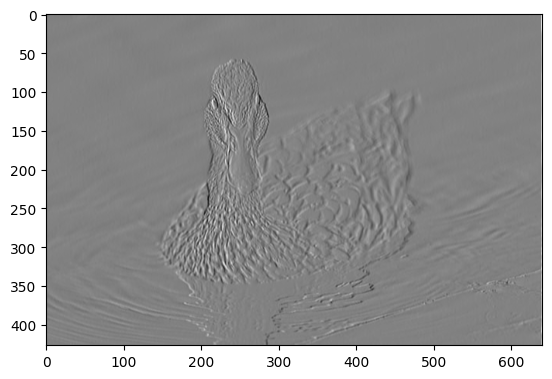

In [ ]:
h_a = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
])

im = read_im("images/duck.jpeg")
im_sobel = convolve_im(im, h_a)
im_sobel = normalize(im_sobel)

plt.imshow(im_sobel)
save_im("results/duck_sobel.jpeg", im_sobel)

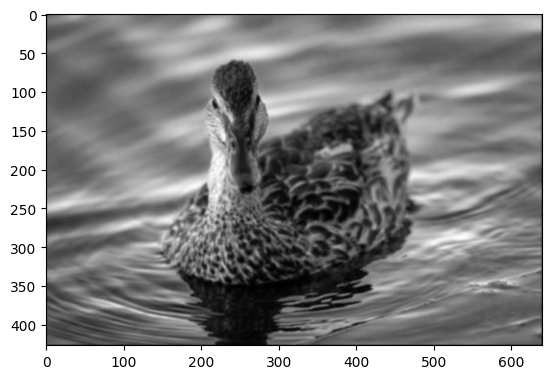

In [ ]:
h_b = 1 / 256  * np.array([
        [1, 4, 6, 4, 1],
        [4, 16, 24, 16, 4],
        [6, 24, 36, 24, 6],
        [4, 16, 24, 16, 4],
        [1, 4, 6, 4, 1]
    ])
 
im_smoothed = convolve_im(im, h_b)
im_smoothed = normalize(im_smoothed)

plt.imshow(im_smoothed, cmap='gray')
save_im("results/duck_smoothed.jpeg", im_smoothed)